# Estudo — substituto de perfil (posição axial como entrada) e PINN com o resíduo do modelo

Duas extensões ao substituto da §5.7 (issue 010): (1) a rede recebe também s = x/L e devolve o perfil
P(x), T(x), com a condição de entrada imposta pela forma y = y_in − s·g; (2) com poucos perfis de treino,
a perda ganha o resíduo das equações do modelo de não escorregamento, r = du/dx − f(x, u), avaliado em
pontos de colocação (P_in, T_in, m, s) que não foram simulados (PINN). Lê `runs/surrogate/*_profile.npz`
(300 perfis por trecho, 51 pontos), os modelos em `models/surrogate/` e `runs/surrogate/`, e o resumo do
estudo `runs/surrogate/pinn_study.json` (produzido por `surrogate.pipeline --steps pinn`). Não simula.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()))

import numpy as np

from dissertation.notebook_utils import ROOT, RUNS, plt, save, table

from surrogate.dataset import load_dataset
from surrogate.profile import ProfileMLP, evaluate_profile

SEG = {"well": "poço", "line": "linha de escoamento", "riser": "riser"}
SR = RUNS / "surrogate"
MODELS = ROOT / "models" / "surrogate"
ds = {s: load_dataset(SR / f"{s}_profile.npz") for s in SEG}
full = {s: ProfileMLP.load(MODELS / f"{s}_profile.json") for s in SEG}
study = json.load(open(SR / "pinn_study.json")) if (SR / "pinn_study.json").exists() else {}
sparse = {s: ProfileMLP.load(SR / f"{s}_profile_n20.json") for s in SEG if (SR / f"{s}_profile_n20.json").exists()}
pinn = {s: ProfileMLP.load(MODELS / f"{s}_pinn.json") for s in SEG if (MODELS / f"{s}_pinn.json").exists()}
pinn0 = {
    s: ProfileMLP.load(SR / f"{s}_pinn_from_scratch.json") for s in SEG if (SR / f"{s}_pinn_from_scratch.json").exists()
}
hist = {s: np.load(SR / f"history_{s}_profile.npz") for s in SEG}
print("perfis:", {s: d["profiles"].shape for s, d in ds.items()}, "| estudo PINN:", list(study))


def test_idx(s):
    return hist[s]["test_idx"]

perfis: {'well': (300, 51, 2), 'line': (300, 51, 2), 'riser': (300, 51, 2)} | estudo PINN: ['well', 'line', 'riser']


## 1. Substituto de perfil com todos os perfis de treino (210 por trecho)

Rede de 2 camadas × 32 neurónios (tanh), Adam 0,01, 3000 épocas em lote completo, sobre 210 × 50
pontos. Erros nos 90 perfis de teste, em todos os pontos e só na saída (comparável ao substituto da §5.7).

| trecho | parâmetros | RMSE P [bar] | RMSE T [K] | máx |ΔP| | máx |ΔT| | saída RMSE P | saída RMSE T | saída erro % P | saída erro % T |
|---|---|---|---|---|---|---|---|---|---|
| poço | 1282 | 0.019 | 0.150 | 0.17 | 1.96 | 0.046 | 0.215 | 0.044 % | 0.019 % |
| linha de escoamento | 1282 | 0.110 | 0.239 | 0.57 | 4.60 | 0.186 | 0.510 | 0.256 % | 0.049 % |
| riser | 1282 | 0.015 | 0.083 | 0.21 | 1.30 | 0.025 | 0.138 | 0.025 % | 0.007 % |
figura: notebooks/figs/nb_study_profile_full.png


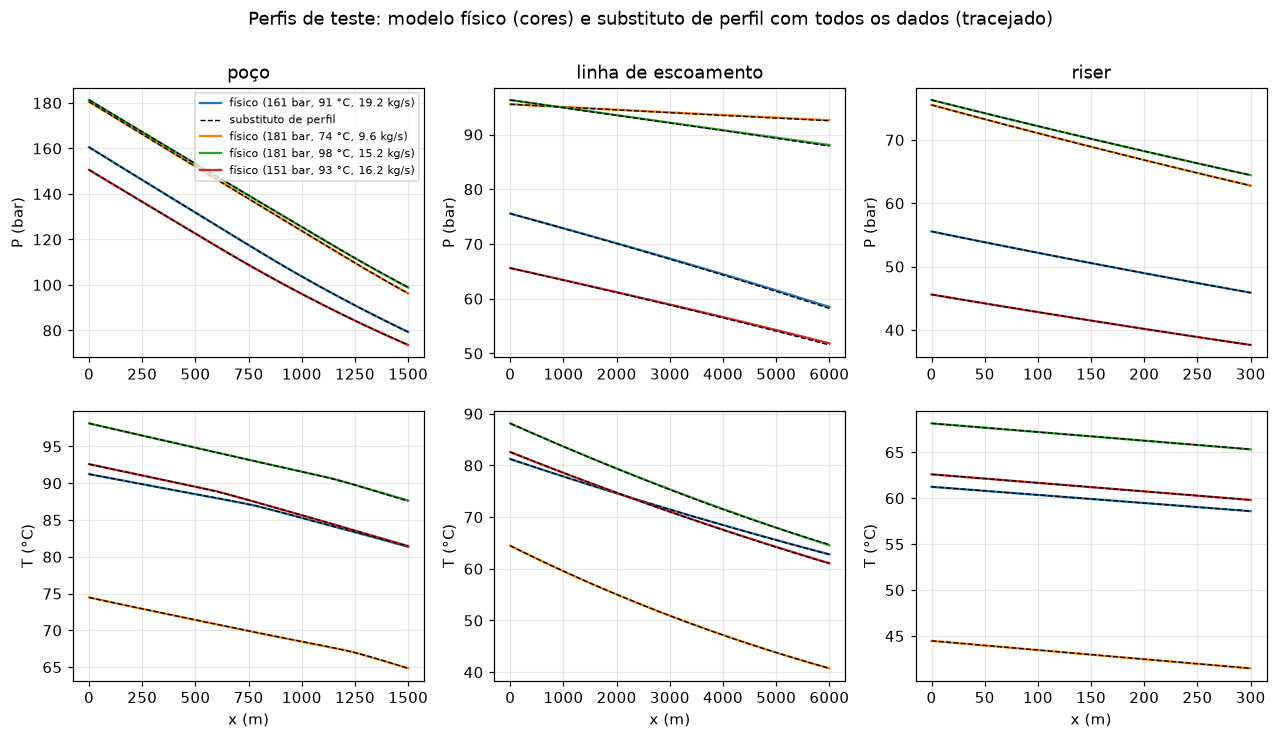

In [2]:
rows = []
for s, name in SEG.items():
    t = full[s].mlp.meta["test_profile"]
    rows.append(
        (
            name,
            full[s].mlp.n_parameters,
            f"{t['rmse'][0]:.3f}",
            f"{t['rmse'][1]:.3f}",
            f"{t['max_abs_error'][0]:.2f}",
            f"{t['max_abs_error'][1]:.2f}",
            f"{t['outlet_rmse'][0]:.3f}",
            f"{t['outlet_rmse'][1]:.3f}",
            f"{t['outlet_mean_percent_error'][0]:.3f} %",
            f"{t['outlet_mean_percent_error'][1]:.3f} %",
        )
    )
table(
    rows,
    [
        "trecho",
        "parâmetros",
        "RMSE P [bar]",
        "RMSE T [K]",
        "máx |ΔP|",
        "máx |ΔT|",
        "saída RMSE P",
        "saída RMSE T",
        "saída erro % P",
        "saída erro % T",
    ],
)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, (s, name) in enumerate(SEG.items()):
    d = ds[s]
    L = float(d["x_out"][-1])
    idx = test_idx(s)[:4]
    for k, i in enumerate(idx):
        P_in, T_in, m = d["X"][i]
        prof = full[s].predict(P_in, T_in, m, d["x_out"] / L)
        col = plt.rcParams["axes.prop_cycle"].by_key()["color"][k]
        axes[0, j].plot(
            d["x_out"],
            d["profiles"][i, :, 0] / 1e5,
            color=col,
            label=f"físico ({P_in:.0f} bar, {T_in - 273.15:.0f} °C, {m:.1f} kg/s)" if j == 0 else None,
        )
        axes[0, j].plot(
            d["x_out"],
            prof[:, 0],
            "--",
            color="k",
            lw=0.9,
            label="substituto de perfil" if (j == 0 and k == 0) else None,
        )
        axes[1, j].plot(d["x_out"], d["profiles"][i, :, 1] - 273.15, color=col)
        axes[1, j].plot(d["x_out"], prof[:, 1] - 273.15, "--", color="k", lw=0.9)
    axes[0, j].set_title(name)
    axes[0, j].set_ylabel("P (bar)")
    axes[1, j].set_ylabel("T (°C)")
    axes[1, j].set_xlabel("x (m)")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Perfis de teste: modelo físico (cores) e substituto de perfil com todos os dados (tracejado)")
save(fig, "nb_study_profile_full")

### Ao longo de todo o sistema, num só eixo

Caso de referência (170 bar, 80 °C, 20 kg/s, fluido da Tabela 6): modelo físico contra os três substitutos
de perfil em série, cada trecho alimentado pela entrada física do trecho (mede o ajuste) ou pela saída do
substituto anterior (encadeado: mede o uso real); painéis de erro em baixo; a linha de escoamento sombreada.

figura: notebooks/figs/nb_study_profile_system.png


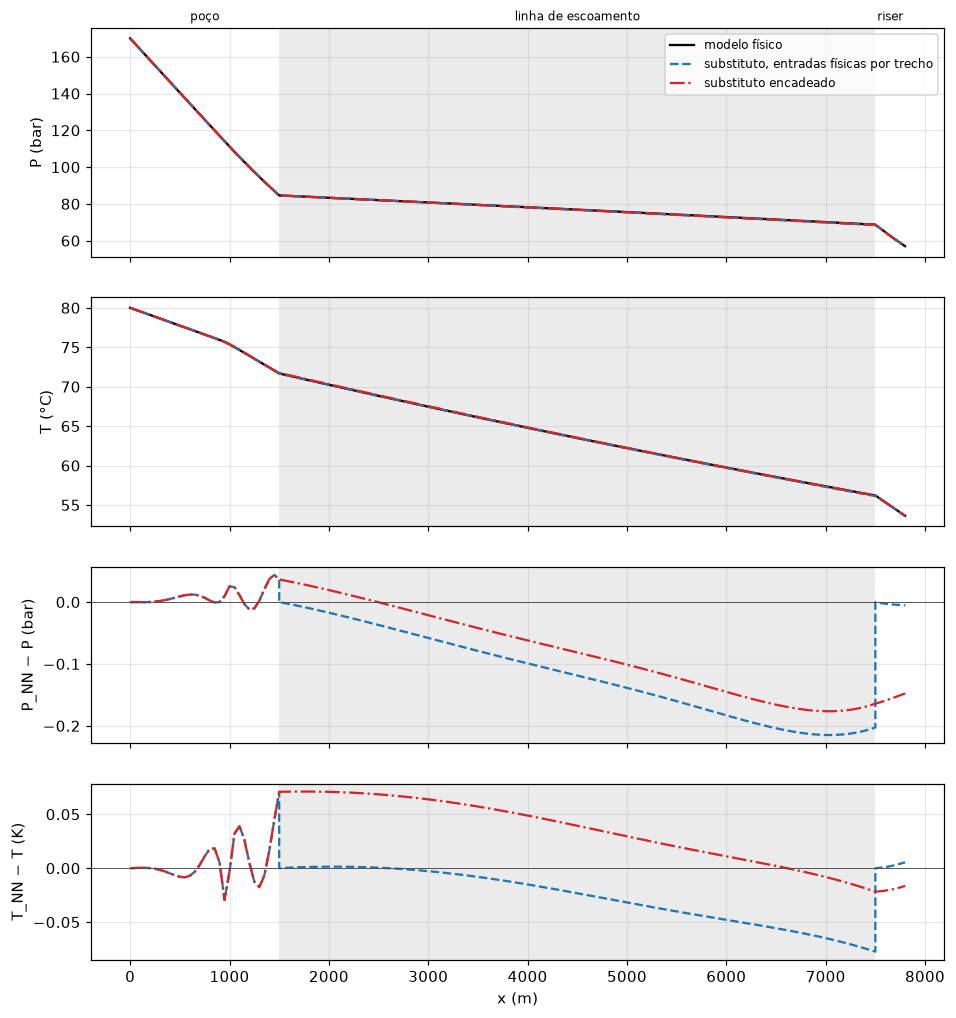

In [3]:
from cmfsim import load_run

SYSTEM = (("well", 0.0, 1500.0), ("line", 1500.0, 7500.0), ("riser", 7500.0, 7800.0))
ref = load_run(SR / "offshore_table6_noslip.npz")


def system_profiles(models, chained):
    xs, Ps, Ts = [], [], []
    inlet = ref.case_dict["boundary"]["inlet"]
    P_in, T_in, m = inlet["P"] / 1e5, inlet["T"], inlet["m"]
    for seg, x0, x1 in SYSTEM:
        if not chained:
            P_in, T_in = np.interp(x0, ref.x, ref.P) / 1e5, np.interp(x0, ref.x, ref.T)
        x = ref.x[(ref.x >= x0) & (ref.x <= x1)]
        prof = models[seg].predict(P_in, T_in, m, (x - x0) / (x1 - x0))
        xs.append(x)
        Ps.append(prof[:, 0])
        Ts.append(prof[:, 1])
        P_in, T_in = prof[-1, 0], prof[-1, 1]
    return np.concatenate(xs), np.concatenate(Ps), np.concatenate(Ts)


def shade(axes):
    for ax in axes:
        ax.axvspan(1500.0, 7500.0, color="0.92", lw=0)
    for seg, x0, x1 in SYSTEM:
        axes[0].text(0.5 * (x0 + x1), 1.02, SEG[seg], transform=axes[0].get_xaxis_transform(), ha="center", va="bottom", fontsize=8)


fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True, gridspec_kw={"height_ratios": [1.3, 1.3, 1, 1]})
axes[0].plot(ref.x, ref.P / 1e5, "k", label="modelo físico")
axes[1].plot(ref.x, ref.T - 273.15, "k")
for chained, col, ls, lab in ((False, "tab:blue", "--", "substituto, entradas físicas por trecho"), (True, "tab:red", "-.", "substituto encadeado")):
    x, Pn, Tn = system_profiles(full, chained)
    axes[0].plot(x, Pn, ls, color=col, label=lab)
    axes[1].plot(x, Tn - 273.15, ls, color=col)
    axes[2].plot(x, Pn - np.interp(x, ref.x, ref.P) / 1e5, ls, color=col)
    axes[3].plot(x, Tn - np.interp(x, ref.x, ref.T), ls, color=col)
for ax, lab in zip(axes, ("P (bar)", "T (°C)", "P_NN − P (bar)", "T_NN − T (K)")):
    ax.set_ylabel(lab)
    ax.grid(alpha=0.3)
for ax in axes[2:]:
    ax.axhline(0, color="0.3", lw=0.6)
axes[3].set_xlabel("x (m)")
shade(axes)
axes[0].legend(fontsize=8)
save(fig, "nb_study_profile_system")

## 2. Dados escassos: 20 perfis de treino, com e sem o resíduo físico

Mesma arquitetura, 20 perfis de treino (1000 pontos). «PINN (a partir do modelo de dados)» parte dos
pesos do modelo só de dados e continua o treino com λ·EQM(resíduo escalado) em pontos de colocação
amostrados por hipercubo latino nas faixas do trecho; «PINN (do zero)» treina a perda completa desde a
inicialização. O resíduo é escalado pela mediana de |du/dx| dos perfis gravados; RMS ≈ 1 significa
desvios da ordem da inclinação típica do perfil. Erros nos mesmos 90 perfis de teste.

poço: 60 pontos de colocação, λ = 1.0, 300 épocas, 209 s
linha de escoamento: 60 pontos de colocação, λ = 1.0, 300 épocas, 227 s
riser: 60 pontos de colocação, λ = 1.0, 300 épocas, 537 s
| trecho | modelo | perfis de treino | RMSE P [bar] | RMSE T [K] | máx |ΔP| | máx |ΔT| | RMS do resíduo |
|---|---|---|---|---|---|---|---|
| poço | só dados, 210 perfis | 210 | 0.019 | 0.150 | 0.17 | 1.96 | 0.046 |
| poço | só dados, 20 perfis | 20 | 0.182 | 1.320 | 1.07 | 10.40 | 0.139 |
| poço | PINN (a partir do modelo de dados) | 20 | 0.147 | 0.614 | 1.11 | 6.43 | 0.006 |
| poço | PINN (do zero) | 20 | 0.156 | 0.655 | 0.88 | 6.91 | 0.042 |
| linha de escoamento | só dados, 210 perfis | 210 | 0.110 | 0.239 | 0.57 | 4.60 | 0.030 |
| linha de escoamento | só dados, 20 perfis | 20 | 0.832 | 3.083 | 12.20 | 12.23 | 0.369 |
| linha de escoamento | PINN (a partir do modelo de dados) | 20 | 0.171 | 1.134 | 3.00 | 10.70 | 0.010 |
| linha de escoamento | PINN (do zero) | 20 | 0.212 | 0.857 | 2.98 | 7.99 | 0

figura: notebooks/figs/nb_study_pinn_history.png


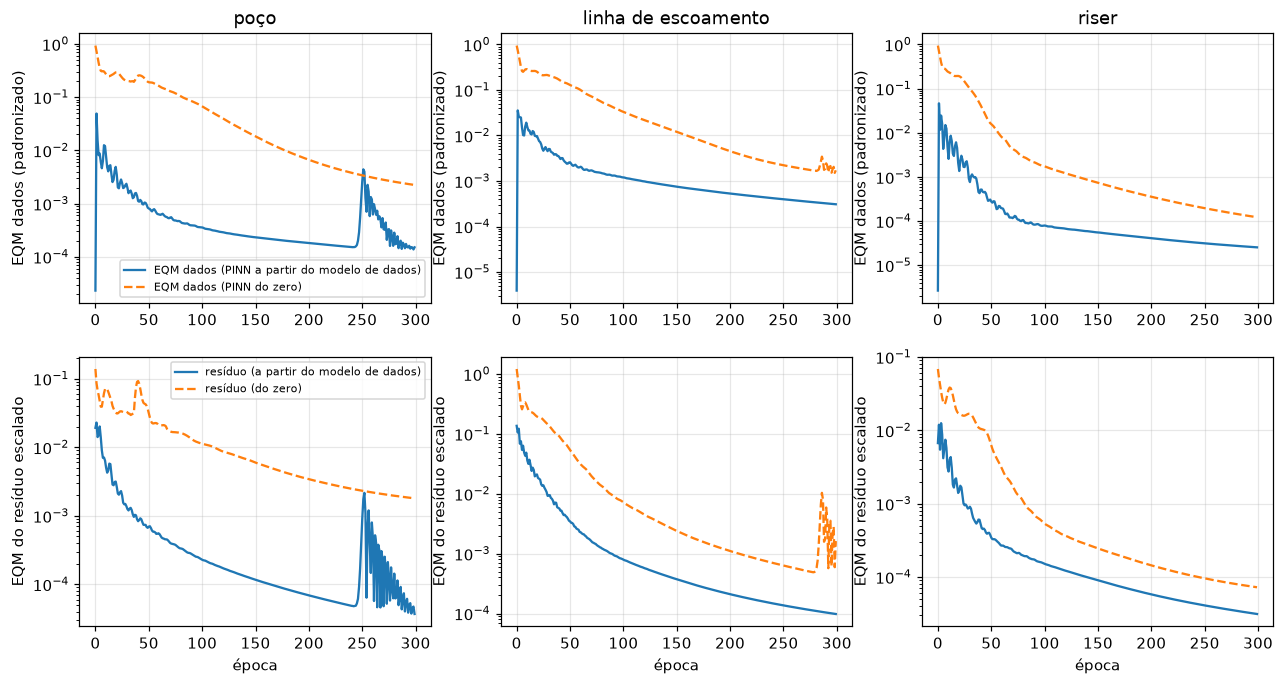

figura: notebooks/figs/nb_study_pinn_profiles.png


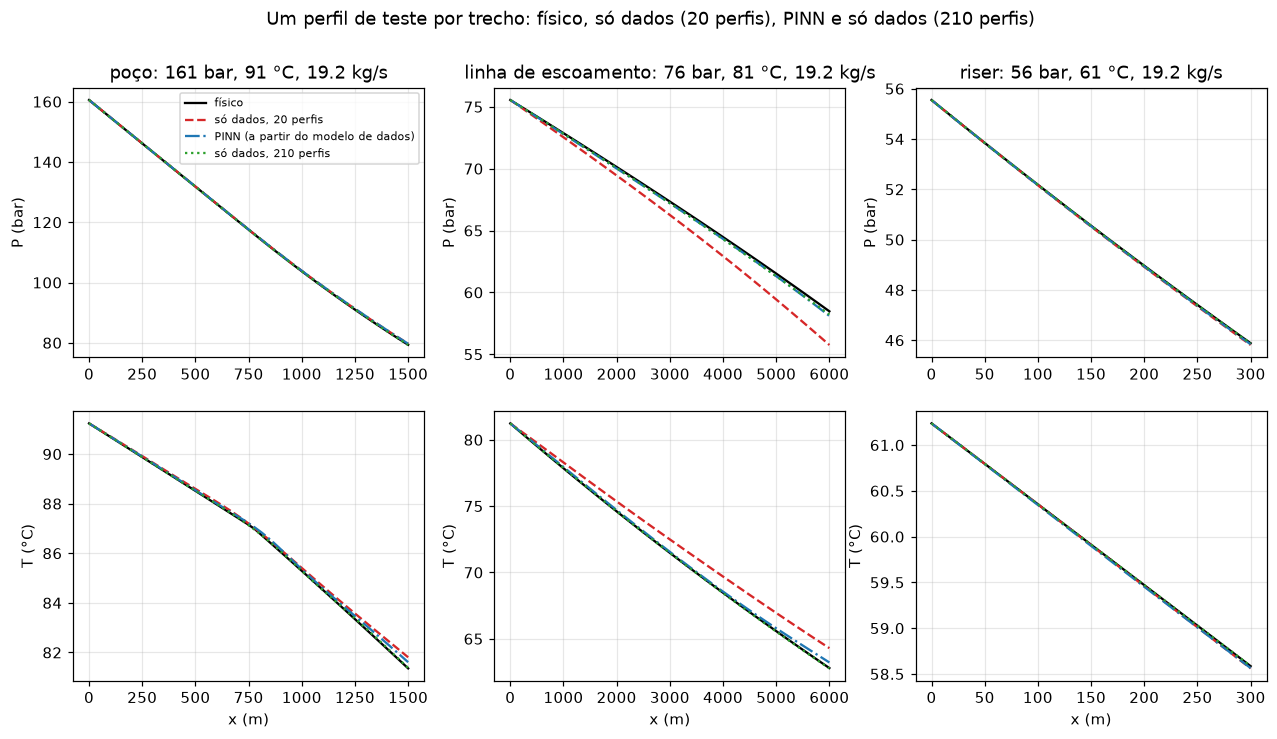

figura: notebooks/figs/nb_study_pinn_system.png


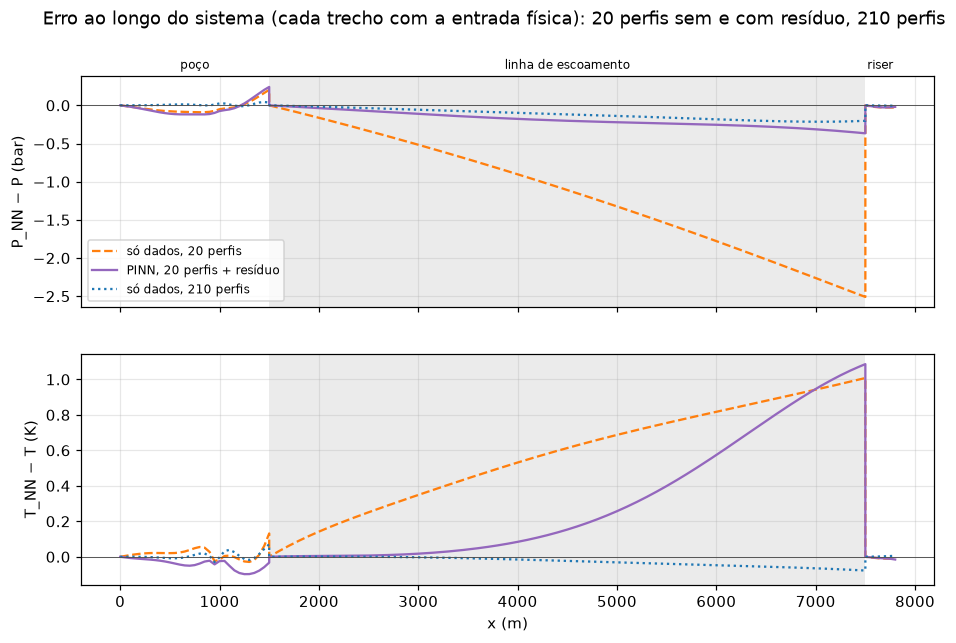

In [4]:
LABELS = {
    "data_full": "só dados, 210 perfis",
    "data_sparse": "só dados, 20 perfis",
    "pinn_from_sparse": "PINN (a partir do modelo de dados)",
    "pinn_from_scratch": "PINN (do zero)",
}
if study:
    rows = []
    for s, name in SEG.items():
        st = study[s]
        for key, lab in LABELS.items():
            r = st["models"][key]
            t = r["test_profile"]
            rows.append(
                (
                    name,
                    lab,
                    r["n_train_profiles"],
                    f"{t['rmse'][0]:.3f}",
                    f"{t['rmse'][1]:.3f}",
                    f"{t['max_abs_error'][0]:.2f}",
                    f"{t['max_abs_error'][1]:.2f}",
                    f"{r['residual_rms']:.3f}",
                )
            )
        print(
            f"{name}: {st['n_collocation']} pontos de colocação, λ = {st['lambda_phys']}, {st['epochs']} épocas, {st['cpu']:.0f} s"
        )
    table(
        rows,
        [
            "trecho",
            "modelo",
            "perfis de treino",
            "RMSE P [bar]",
            "RMSE T [K]",
            "máx |ΔP|",
            "máx |ΔT|",
            "RMS do resíduo",
        ],
    )

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for j, (s, name) in enumerate(SEG.items()):
        h = np.load(SR / f"history_{s}_pinn.npz")["history"]
        h0 = np.load(SR / f"history_{s}_pinn_from_scratch.npz")["history"]
        ax = axes[0, j]
        ax.semilogy(h[:, 0], label="EQM dados (PINN a partir do modelo de dados)")
        ax.semilogy(h0[:, 0], "--", label="EQM dados (PINN do zero)")
        ax.set_title(name)
        ax.set_ylabel("EQM dados (padronizado)")
        ax.grid(alpha=0.3)
        ax = axes[1, j]
        ax.semilogy(h[:, 1], label="resíduo (a partir do modelo de dados)")
        ax.semilogy(h0[:, 1], "--", label="resíduo (do zero)")
        ax.set_ylabel("EQM do resíduo escalado")
        ax.set_xlabel("época")
        ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7)
    axes[1, 0].legend(fontsize=7)
    save(fig, "nb_study_pinn_history")

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for j, (s, name) in enumerate(SEG.items()):
        d = ds[s]
        L = float(d["x_out"][-1])
        i = int(test_idx(s)[0])
        P_in, T_in, m = d["X"][i]
        ss = d["x_out"] / L
        curves = [("físico", d["profiles"][i, :, 0] / 1e5, d["profiles"][i, :, 1] - 273.15, "k", "-")]
        for key, model, col, ls in (
            ("data_sparse", sparse.get(s), "tab:red", "--"),
            ("pinn_from_sparse", pinn.get(s), "tab:blue", "-."),
            ("data_full", full[s], "tab:green", ":"),
        ):
            if model is not None:
                pr = model.predict(P_in, T_in, m, ss)
                curves.append((LABELS[key], pr[:, 0], pr[:, 1] - 273.15, col, ls))
        for lab, Pc, Tc, col, ls in curves:
            axes[0, j].plot(d["x_out"], Pc, ls, color=col, label=lab if j == 0 else None)
            axes[1, j].plot(d["x_out"], Tc, ls, color=col)
        axes[0, j].set_title(f"{name}: {P_in:.0f} bar, {T_in - 273.15:.0f} °C, {m:.1f} kg/s")
        axes[0, j].set_ylabel("P (bar)")
        axes[1, j].set_ylabel("T (°C)")
        axes[1, j].set_xlabel("x (m)")
        for ax in axes[:, j]:
            ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle("Um perfil de teste por trecho: físico, só dados (20 perfis), PINN e só dados (210 perfis)")
    save(fig, "nb_study_pinn_profiles")

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    for models_, col, ls, lab in ((sparse, "tab:orange", "--", "só dados, 20 perfis"), (pinn, "tab:purple", "-", "PINN, 20 perfis + resíduo"), (full, "tab:blue", ":", "só dados, 210 perfis")):
        if len(models_) < 3:
            continue
        x, Pn, Tn = system_profiles(models_, chained=False)
        axes[0].plot(x, Pn - np.interp(x, ref.x, ref.P) / 1e5, ls, color=col, label=lab)
        axes[1].plot(x, Tn - np.interp(x, ref.x, ref.T), ls, color=col)
    for ax, lab in zip(axes, ("P_NN − P (bar)", "T_NN − T (K)")):
        ax.set_ylabel(lab)
        ax.axhline(0, color="0.3", lw=0.6)
        ax.grid(alpha=0.3)
    axes[1].set_xlabel("x (m)")
    shade(axes)
    axes[0].legend(fontsize=8)
    fig.suptitle("Erro ao longo do sistema (cada trecho com a entrada física): 20 perfis sem e com resíduo, 210 perfis")
    save(fig, "nb_study_pinn_system")
else:
    print("estudo PINN ainda não corrido (runs/surrogate/pinn_study.json)")

## 3. Sobreajuste, viés e a escolha do conjunto de teste

`surrogate.validation`: validação cruzada 5-fold do substituto de saída; curvas de aprendizagem (erro de
teste e de treino contra o número de perfis de treino, 3 repetições: a diferença treino–teste mede o
sobreajuste e o desvio entre repetições a variância); viés (erro médio com sinal); e três estratégias de
divisão para os perfis, por perfil (condições de entrada novas), por posição (30 % dos pontos ao longo de x
nunca vistos: interpolação em x) e por bloco (teste = perfis com P_in no topo da faixa: extrapolação). O
resíduo físico é ainda avaliado num conjunto de colocação nunca usado no treino.

| trecho | modelo, conjunto de treino | RMSE teste P / T (média ± desvio) | teste − treino | viés P / T |
|---|---|---|---|---|
| poço | saída, 5-fold (210 treino) | 0.144 ± 0.053 / 0.379 ± 0.208 | +0.036 / +0.168 | +0.006 / +0.020 |
| poço | perfil, 20 treino, divisão por perfil | 0.189 ± 0.050 / 1.174 ± 0.253 | +0.172 / +1.147 | +0.023 / +0.059 |
| poço | perfil, 210 treino, divisão por perfil | 0.030 ± 0.006 / 0.150 ± 0.076 | +0.008 / +0.114 | +0.001 / +0.015 |
| poço | perfil, 20 treino, divisão por posição | 0.030 ± 0.011 / 0.020 ± 0.002 | +0.007 / +0.002 | +0.003 / -0.001 |
| poço | perfil, 210 treino, divisão por posição | 0.030 ± 0.006 / 0.041 ± 0.002 | +0.005 / +0.003 | -0.007 / +0.003 |
| poço | perfil, 20 treino, divisão por bloco | 0.413 ± 0.088 / 1.058 ± 0.122 | +0.392 / +1.021 | +0.040 / +0.107 |
| poço | perfil, 210 treino, divisão por bloco | 0.044 ± 0.009 / 0.073 ± 0.014 | +0.021 / +0.037 | +0.002 / +0.016 |
| linha de escoamento | saída, 5-fold (210 treino) | 0.548 ± 

figura: notebooks/figs/nb_study_validation.png


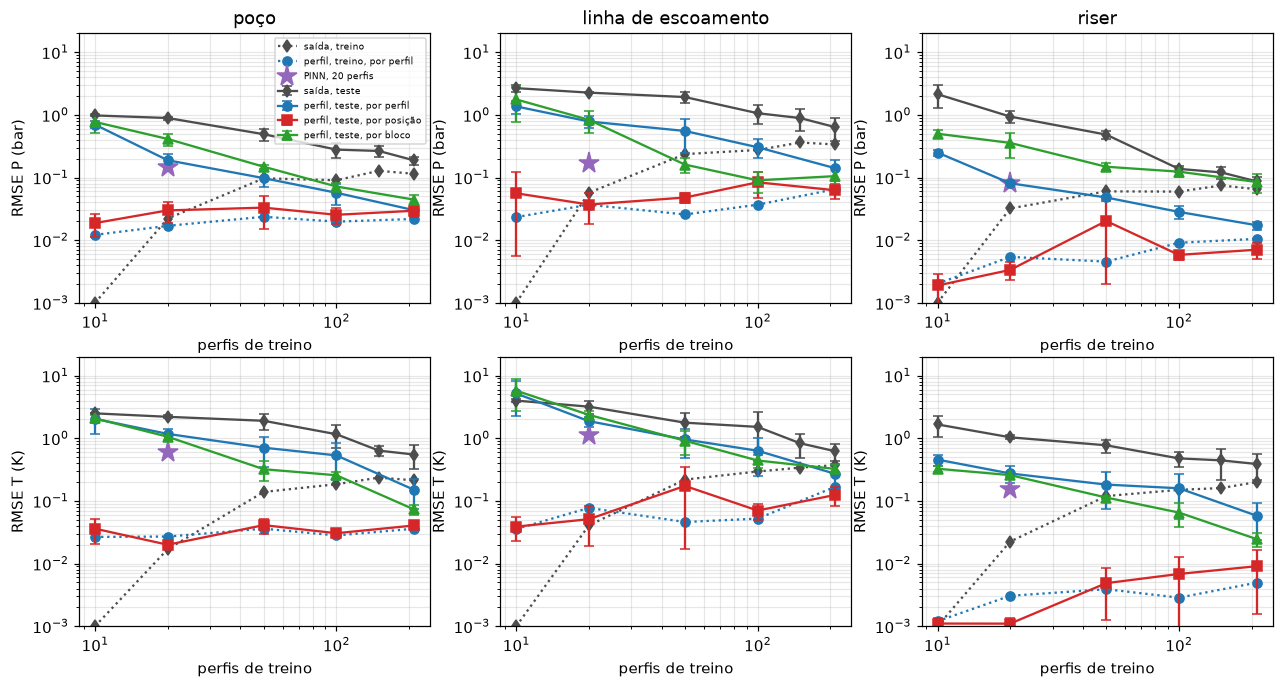

In [5]:
vpath = SR / "validation.json"
if vpath.exists():
    val = json.load(open(vpath))
    rows = []
    for s, name in SEG.items():
        kf = val[s]["outlet"]["kfold"]["summary"]
        rows.append((name, "saída, 5-fold (210 treino)", f"{kf['test_rmse_mean'][0]:.3f} ± {kf['test_rmse_std'][0]:.3f} / {kf['test_rmse_mean'][1]:.3f} ± {kf['test_rmse_std'][1]:.3f}", f"{kf['gap_mean'][0]:+.3f} / {kf['gap_mean'][1]:+.3f}", f"{kf['bias_mean'][0]:+.3f} / {kf['bias_mean'][1]:+.3f}"))
        for mode, lab in (("profile", "por perfil"), ("position", "por posição"), ("block", "por bloco")):
            for c in val[s]["profile"][mode]["curve"]:
                if c["n_train"] in (20, 210):
                    rows.append((name, f"perfil, {c['n_train']} treino, divisão {lab}", f"{c['test_rmse_mean'][0]:.3f} ± {c['test_rmse_std'][0]:.3f} / {c['test_rmse_mean'][1]:.3f} ± {c['test_rmse_std'][1]:.3f}", f"{c['gap_mean'][0]:+.3f} / {c['gap_mean'][1]:+.3f}", f"{c['bias_mean'][0]:+.3f} / {c['bias_mean'][1]:+.3f}"))
    table(rows, ["trecho", "modelo, conjunto de treino", "RMSE teste P / T (média ± desvio)", "teste − treino", "viés P / T"])
    rows = []
    for s, name in SEG.items():
        held = val[s]["profile"].get("heldout_residual", {})
        for key, lab in LABELS.items():
            if s in study and key in study[s]["models"]:
                rows.append((name, lab, f"{study[s]['models'][key]['residual_rms']:.3f}", f"{held[key]:.3f}" if key in held else "—"))
    table(rows, ["trecho", "modelo", "resíduo, colocação de treino", "resíduo, colocação nunca vista"])

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for j, (s, name) in enumerate(SEG.items()):
        for i, (col, unit) in enumerate((("P", "bar"), ("T", "K"))):
            ax = axes[i, j]
            floor = 1e-3  # erros de treino nulos (interpolação exata) no chão do eixo logarítmico

            def curva(lc, fmt, color, label, train=False):
                n = np.array([c["n_train"] for c in lc], float)
                if train:
                    ax.plot(n, np.maximum([c["train_rmse_mean"][i] for c in lc], floor), fmt, color=color, label=label)
                    return
                m_ = np.array([c["test_rmse_mean"][i] for c in lc])
                sd = np.array([c["test_rmse_std"][i] for c in lc])
                ax.errorbar(n, m_, yerr=[np.minimum(sd, 0.9 * m_), sd], fmt=fmt, color=color, capsize=3, label=label)

            curva(val[s]["outlet"]["learning_curve"]["curve"], "d-", "0.3", "saída, teste")
            curva(val[s]["outlet"]["learning_curve"]["curve"], "d:", "0.3", "saída, treino", train=True)
            for mode, lab, color, mk in (("profile", "perfil, teste, por perfil", "tab:blue", "o"), ("position", "perfil, teste, por posição", "tab:red", "s"), ("block", "perfil, teste, por bloco", "tab:green", "^")):
                curva(val[s]["profile"][mode]["curve"], mk + "-", color, lab)
                if mode == "profile":
                    curva(val[s]["profile"][mode]["curve"], mk + ":", color, "perfil, treino, por perfil", train=True)
            ax.set_ylim(floor, 20.0)
            if s in study:
                ax.plot([20], [study[s]["models"]["pinn_from_sparse"]["test_profile"]["rmse"][i]], "*", color="tab:purple", ms=14, label="PINN, 20 perfis")
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlabel("perfis de treino")
            ax.set_ylabel(f"RMSE {col} ({unit})")
            ax.grid(alpha=0.3, which="both")
            if i == 0:
                ax.set_title(name)
    axes[0, 0].legend(fontsize=6)
    save(fig, "nb_study_validation")
else:
    print("validação ainda não corrida (runs/surrogate/validation.json)")